# COGS 108 - Data Checkpoint

## Authors

- Zoya Jhaveri: Methodology, Writing – review & editing
- Vrindha Prakash: Analysis, Software, Visualization
- Issac Roy: Analysis, Software, Visualization
- Anagha Kamath: Project administration, Background research, Software

## Research Question

Our research investigates how effectively Body Mass Index (BMI) predicts overall health outcomes compared to lifestyle factors such as daily calorie intake, exercise frequency, and hours of sleep. Specifically, we aim to determine whether these behavioral indicators are stronger predictors of health status which are measured by the presence of diabetes, high blood pressure, or high cholesterol rather than BMI alone. Prior studies suggest that while BMI is widely used as a health indicator, it may not fully capture the effects of lifestyle behaviors on metabolic health. To address this, we will analyze the relationships between BMI, lifestyle factors, and health outcomes using correlation and multiple regression analyses, controlling for demographic variables such as age and sex. This project will evaluate the predictive validity of BMI relative to lifestyle-based health metrics to determine whether BMI is a sufficient standalone indicator of overall health.

## Background and Prior Work

For years, the concept of BMI, or Body Mass Index, has been used as a reliable and quick way to determine an individual’s general health status. This numerical value, derived from a person’s weight and height, provides a simple estimate of whether someone is underweight, at a healthy weight, overweight, or obese. However, while BMI is helpful for establishing broad population trends, it fails to account for key individual differences such as fat distribution, metabolic rate, and muscle mass, which can significantly influence overall health outcomes.

In the past, multiple studies have explored what physical and biochemical factors most accurately predict chronic health conditions. One such study, “Predicting the Onset of Diabetes with Machine Learning Methods,” published in Frontiers in Public Health, used advanced machine learning models to identify risk factors contributing to diabetes onset. The best performing models, two-class decision jungle and two-class boosted decision tree, achieved AUC scores of 0.976 and 0.991, demonstrating highly accurate prediction capabilities based on diverse health metrics rather than BMI alone.<sup><a href="#ref1">1</a></sup>

Similarly, a Nature study titled “Identifying Top Ten Predictors of Type 2 Diabetes through Machine Learning Analysis of UK Biobank Data” (2024) used large scale data and predictive modeling to determine which biological and lifestyle variables most strongly indicate diabetes risk. The top predictors for males were HbA1c, plasma glucose, BMI, family history of diabetes, and GGT, suggesting that biochemical markers outperform BMI in predicting disease outcomes.<sup><a href="#ref2">2</a></sup>

Beyond published studies, open-source data projects have also investigated diabetes prediction. A Kaggle project titled “Diabetes Prediction” by Abdollahii tested multiple machine learning models such as CatBoost, SVM, XGBoost, and Random Forest on clinical and behavioral data. The CatBoost model achieved the highest AUC, with all others scoring above 0.95, indicating that ensemble models effectively capture the multifaceted nature of diabetes risk, including BMI and metabolic factors.<sup><a href="#ref3">3</a></sup>

Another Kaggle analysis, “Diabetes EDA & Random Forest HP” by Tumpan Jawat, focused on feature importance analysis using a Random Forest classifier. The study found HbA1c level to be the most important predictor of diabetes (importance = 0.44), followed by blood glucose level (0.32), age (0.14), and BMI (0.06). Other factors, including hypertension and heart disease, showed minor predictive relevance, while smoking history and gender had minimal impact. These results reinforce that although BMI plays a role in diabetes prediction, biochemical and age-related variables are far stronger indicators of disease likelihood.<sup><a href="#ref4">4</a></sup>


<a name="ref1">1.</a> Predicting the Onset of Diabetes with Machine Learning Methods. Frontiers in Public Health. https://pmc.ncbi.nlm.nih.gov/articles/PMC10057336/

<a name="ref2">2.</a> Identifying Top Ten Predictors of Type 2 Diabetes through Machine Learning Analysis of UK Biobank Data. Nature Scientific Reports, 2024. https://www.nature.com/articles/s41598-024-52023-5

<a name="ref3">3.</a> Abdollahii, A. Diabetes Prediction. Kaggle Notebook. https://www.kaggle.com/code/aabdollahii/diabetes-prediction

<a name="ref4">4.</a> Jawat, T. Diabetes EDA & Random Forest HP. Kaggle Notebook. https://www.kaggle.com/code/tumpanjawat/diabetes-eda-random-forest-hp

## Hypothesis


We predict that BMI alone is a weaker predictor of overall health outcomes than behavioral and biochemical indicators such as calorie intake, hours of sleep, exercise frequency, and blood glucose levels. Specifically, we expect that higher blood glucose levels and higher cholesterol levels will be associated with poorer health outcomes. We also anticipate that blood glucose levels will have the strongest influence, as they directly reflect metabolic regulation and risk for conditions such as diabetes. We expect this because prior research suggests that BMI does not distinguish between muscle and fat mass or account for behavioral habits that directly affect metabolic health. In contrast, lifestyle habits directly influence energy balance, cardiovascular function, and metabolic regulation, making them more accurate indicators of overall health. Therefore, individuals with healthier lifestyles may exhibit better health outcomes even if their BMI falls outside the “normal” range.

## Data

### Data overview

- Dataset #1
  - Dataset Name: Diabetes Health Indicators Dataset
  - Link to the dataset: https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset/data
  - Number of observations: 253,680
  - Number of variables: 22
  - Description of the variables most relevant to this project: Key variables include a binary diabetes indicator, high blood pressure, high cholesterol, cholesterol check, BMI, smoking status, history of stroke, heart disease or attack, physical activity, fruit and vegetable consumption, heavy alcohol consumption, healthcare access, inability to see a doctor due to cost, general health, mental health, physical health, difficulty walking, sex, age, education level, and income.
  - Descriptions of any shortcomings this dataset has with repsect to the project: Most of the columns are binary which means that we can't run any regressions on this, but rather we have to use classification models. This isn't ideal since we lose granularity per data point.
  
- Dataset #2
  - Dataset Name: Diabetes Prediction Dataset
  - Link to the dataset: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset
  - Number of observations: 100,000
  - Number of variables: 9
  - Description of the variables most relevant to this project: Key variables include such as age, gender, Body Mass Index (BMI), hypertension, heart disease, smoking history, HbA1c level, and blood glucose level.
  - Descriptions of any shortcomings this dataset has with repsect to the project: While the columns have more granularity in this dataset, it doesn't have many features to predict off of.

The first dataset contains mostly information about personal life matters such as income, physical health, if they eat fruit or not, etc. while the second dataset is a bit more health focused. This means that we'll run seperate analyses on the two datasets since they focus on different things. For the variables that are shared, such as smoking, the categories used are different so we can't reliably combine the information, which again affirms a need to run seperate analyses.

In [2]:
# Run this code every time when you're actively developing modules in .py files.  It's not needed if you aren't making modules
#
## this code is necessary for making sure that any modules we load are updated here 
## when their source code .py files are modified

%load_ext autoreload
%autoreload 2

In [6]:
# Setup code -- this only needs to be run once after cloning the repo!
# this code downloads the data from its source to the `data/00-raw/` directory
# if the data hasn't updated you don't need to do this again!

# if you don't already have these packages (you should!) uncomment this line
# %pip install requests tqdm

import sys
sys.path.append('./modules') # this tells python where to look for modules to import

import get_data # this is where we get the function we need to download data

# replace the urls and filenames in this list with your actual datafiles
# yes you can use Google drive share links or whatever
# format is a list of dictionaries; 
# each dict has keys of 
#   'url' where the resource is located
#   'filename' for the local filename where it will be stored 
datafiles = [
    { 'url': 'https://www.kaggle.com/api/v1/datasets/download/iammustafatz/diabetes-prediction-dataset', 'filename':'diabetes_prediction.zip'},
    { 'url': 'https://www.kaggle.com/api/v1/datasets/download/alexteboul/diabetes-health-indicators-dataset', 'filename':'diabetes_indicators.zip'}
]

get_data.get_raw(datafiles,destination_directory='data/00-raw/')
get_data.unzip("./data/00-raw/diabetes_indicators.zip")
get_data.unzip("./data/00-raw/diabetes_prediction.zip")

Overall Download Progress:  50%|█████     | 1/2 [00:00<00:00,  2.67it/s]

Successfully downloaded: diabetes_prediction.zip


Overall Download Progress: 100%|██████████| 2/2 [00:01<00:00,  1.44it/s]


Successfully downloaded: diabetes_indicators.zip


WindowsPath('data/00-raw/diabetes_prediction')

### Diabetes Health Indicators Dataset 

This dataset contains several important health-related metrics that help identify risk factors and conditions related to diabetes. 

The primary outcome variable, *Diabetes_012*, classifies individuals as having no diabetes (0), prediabetes (1), or diabetes (2), based on their blood glucose levels or diagnosis status. *BMI (Body Mass Index)* is a continuous measure calculated as weight in kilograms divided by height in meters squared $(\frac{kg}{m^2})$, where values between 18.5-24.9 are considered healthy, 25-29.9 indicate overweight, and 30 or higher suggest obesity. Binary variables such as *HighBP (high blood pressure)* and *HighChol (high cholesterol)* indicate whether the participant has been told they have these conditions, which are both major cardiovascular risk factors. *CholCheck* represents whether an individual had their cholesterol checked within the last five years, serving as a measure of preventive healthcare behavior. *Smoker*, *Stroke*, and *HeartDiseaseorAttack* identify individuals with a history of smoking, stroke, or heart disease/heart attack, which each play a role in chronic disease risk profiles. *PhysActivity* indicates engagement in physical activity outside of work within the past 30 days. *Fruits* and *Veggies* reflects daily fruit and vegetable consumption, both of which relate to lifestyle and health maintenance, each coded as 0 (no) or 1 (yes). Demographic and socioeconomic variables include *Sex* (0 = female, 1 = male), *Age* (categorized from 1 = 18–24 to 13 = 80+), *Education* (1–6 from no schooling to college graduate), and *Income* (1–8 from less than $10,000 to 75,000 or more). Taken together, these metrics offer a broad overview of an individual’s genetic factors, physical health, lifestyle behaviors, and education access, enabling a detailed examination of the factors that influence diabetes risk and general health outcomes. 

While it covers a range of health metrics, one concern about this dataset is that most values are represented in binary or categorical form rather than continuous measurements. This limits the ability to capture nuances and severity levels. For example, values like high blood pressure or cholesterol are given simply as “yes” or “no,” without indicating how elevated the values are.  Similarly, behaviors such as smoking or fruit consumption are reduced to a simple binary distinction, ignoring variation in frequency or quantity. As mentioned above, this means that instead of applying regression models to explore continuous relationships, we are constrained to using classification-based approaches, making it harder to detect subtle trends or variations within the data. Additionally, we know that the data comes from the Behavioral Risk Factor Surveillance System (BRFSS), a large scale health-related telephone survey conducted annually by the CDC. Thus, because the data most likely comes from a self-reported surveys, there is also a risk of recall bias or social desirability bias, where participants may underreport unhealthy habits, smoking, or overreport healthy ones such as fruit consumption. This could make the dataset less representative of the general population, particularly of groups with limited healthcare access, lower socioeconomic status, or lesser healthcare access. Together, these concerns may impact the precision of analyses derived from the dataset, and affect our results.


In [31]:
## YOUR CODE TO LOAD/CLEAN/TIDY/WRANGLE THE DATA GOES HERE
import pandas as pd

indicators = pd.read_csv("data/00-raw/diabetes_indicators/diabetes_012_health_indicators_BRFSS2015.csv")
indicators.head()

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [26]:
indicators.isnull().sum()

Diabetes_012            0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64

Since the columns are all unique and there are no missing values, the data is clean and tidy.

In [10]:
indicators.shape

(253680, 22)

In [17]:
binary_cols = ["HighBP", "HighChol", "CholCheck", "Smoker", "Stroke", "HeartDiseaseorAttack", "PhysActivity", "Fruits", "Veggies", "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Sex"]
other_cols = [col for col in indicators.columns if col not in binary_cols]

In [18]:
indicators[indicators[binary_cols].isin([0, 1]).all(axis=1) == False]

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income


There are no unusual values in the binary columns (they are all 0 and 1 as expected).

<Axes: >

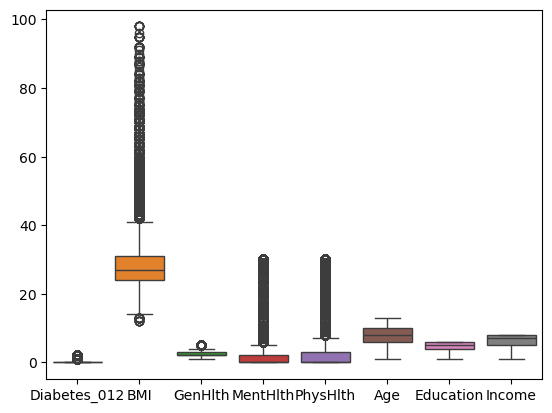

In [14]:
import seaborn as sns
sns.boxplot(data=indicators[other_cols])

The only columns with outliers are `Diabetes`, `BMI`, `GenHlth`, `MentHlth`, and `PhysHlth`.

In [21]:
indicators["Diabetes_012"].unique(), indicators["GenHlth"].unique()

(array([0., 2., 1.]), array([5., 3., 2., 4., 1.]))

The values in `Diabetes` and `GenHlth` aren't unusual either because they adhere to their ordinal scale. The only reason some points were marked as outliers is because the points are concentrated in a few values, e.g. most Diabetes values are 0 indicating no diabetes.

In [23]:
indicators[['BMI', 'MentHlth', 'PhysHlth']].describe()

,BMI,MentHlth,PhysHlth
count,253680.000000,253680.000000,253680.000000
mean,28.382364,3.184772,4.242081
std,6.608694,7.412847,8.717951
min,12.000000,0.000000,0.000000
25%,24.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000
75%,31.000000,2.000000,3.000000
max,98.000000,30.000000,30.000000


The wide range of values for `BMI` also make sense since this data is from the U.S. which has an obesity crisis. As for `MentHlth` and `PhysHlth`, the values reflect how many of the past 30 days weren't good mentally and physically respectively. It makes sense that most people would choose numbers close to 0 but some may have much higher numbers especially if they have some sort of mental health disorder or serious physical injury.

In [28]:
rename_map = {
    "Diabetes_012": "Diabetes",
    "HighBP": "High BP",
    "HighChol": "High Cholesterol",
    "CholCheck": "Cholesterol Check",
    "BMI": "BMI",
    "Smoker": "Smoker",
    "Stroke": "Stroke",
    "HeartDiseaseorAttack": "Heart Disease",
    "PhysActivity": "Physical Activity",
    "Fruits": "Fruit Intake",
    "Veggies": "Veggie Intake",
    "HvyAlcoholConsump": "Heavy Alcohol",
    "AnyHealthcare": "Healthcare Access",
    "NoDocbcCost": "No Doctor Cost",
    "GenHlth": "General Health",
    "MentHlth": "Mental Health",
    "PhysHlth": "Physical Health",
    "DiffWalk": "Difficulty Walking",
    "Sex": "Sex",
    "Age": "Age Group",
    "Education": "Education Level",
    "Income": "Income Level"
}
final_ind = indicators.rename(columns=rename_map)
final_ind.to_csv("data/02-processed/diabetes_indicators.csv", index=False)

### Diabetes Prediction dataset

The dataset contains important metrics that were used to analyze and understand an individual's likelihood of diabetes.   

Variables used to indicate increased risk of diabetes were formatted as a dataset -- Gender, Age, Hypertension, Heart Disease, Smoking history, BMI, HbA1c level, Blood Glucose level. Gender was classified as either male or female as indicated by the patients surveyed. The category of Age (in years) included a wide range from 2 years to 80 years, used as a metric to analyze one's likelihood of having diabetes. Hypertension, a condition where forces of blood against the artery walls are consistently too high, was surveyed among various individuals, and added to the dataset, such that 0 indicated 'No- did not have hypertension', and 1 indicates 'Yes- had hypertension'. Furthermore, each individual's record of heart disease was analyzed, such that 0 indicated 'No- did not have record of heart disease', and 1 indicates 'Yes- had record of heart disease'. Another variable analyzed was each individual's smoking history, where types of responses included were: 'never' smoked, 'current' smoker, or 'no information', 'former' smoker, and 'ever' smoker. Another metric that was identified and measured among surveyed individuals was BMI, which is derived from the mass and height of each individual and calculated as weight divided by (height)^2. The ranges for BMI can be classified under obese(BMI of 30.0 or higher), overweight(BMI of 25.0-29.9), healthy weight (BMI of 18.5 - 24.9), and underweight(BMI of 18.5 or lower, and the BMI numerical value was measured and added to the dataset for the surveyed individuals. Hemoglobin A1c test (HbA1c test), indicated as a percentage, shows one's average level of blood glucose over the past 2-3 months, and was another metric measured among surveyed individuals. HbA1c levels can be classified as -- blood sugar being in the normal range(5.7 or below), at risk for pre-diabetes(5.7-6.4), at risk for diabetes(6.5 or higher). These numerical values were tested and added to the dataset. Another variable measured was blood glucose levels, indicated as milligrams per decileter, of all the surveyed individuals, where 99mg/decileter or lower indicated normal blood sugar, 100-125 mg/decileter fell under the category of pre-diabetic, and 126 or higher fell under the category of diabetic. Lastly, individuals were surveyed on whether or not they had diabetes, where 0 indicated 'No- do not have diabetes' and 1 indicated 'Yes- have diabetes'. Among all the datasets, hypertension, heart disease record, and diagnosis of diabetes were collected as binary data, while Gender and Smoking history were recorded as categorical variables.

One of the primary concerns of this dataset would be that a few of the variables collected were in the form of binary or categorical data as opposed to continuous data, allowing for lack of comparative measurement in severity levels across various individuals, similar to dataset 1. For example, metrics like hypertension, heart disease record, and diagnosis of diabetes were recorded as binary forms of data, which ignores the level of severity and sensitivity to which their body responds to these particular health issues. Thus, in order to plot such a dataset, regression models can't be used to find correlations, but rather classification models must be used to compare, analyze and make predictions from the collected data, which may not be as accurate due to lack of heavy statistical calculations involved. Furthermore, the variable smoking history, which was collected as a categorical variable rather than continuous, ignore factors like frequency for current smokers, or frequency of smoking during the past. Another issue under smoking history included the fact that there were a few individuals that did not provide information on their smoking history, which reduces reprentativeness and introducing bias to the dataset. The data includes a collection of a wide demographic of medical patient data, thus the data would see randomization. However, there could be bias since the data is from medical patients alone and ignores those that do not have healthcare insurance or do not have access to doctors or hospitals. This would make the dataset less representative of the general population, particularly with groups that do not have access to healthcare, are ashamed of smoking, or experience unique severity levels to any of the health issues assessed. In summary, while the dataset provides valuable insights into factors associated with diabetes risk, its reliance on categorical and binary variables, missing data, and potential sampling bias may limit precision and introduce skew in the results.

In [8]:
## YOUR CODE TO LOAD/CLEAN/TIDY/WRANGLE THE DATA GOES HERE
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df_predict = pd.read_csv('data/00-raw/diabetes_prediction/diabetes_prediction_dataset.csv')  #loading the dataset

In [24]:
df_predict.columns = ['Gender', 'Age', 'Hypertension', 'Heart Disease', 'Smoking history', 'BMI', 'HbA1c level', 'Blood Glucose Level', 'Diabetes']
display(df_predict.head())                                  


,Gender,Age,Hypertension,Heart Disease,Smoking history,BMI,HbA1c level,Blood Glucose Level,Diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Since each variable measured is in a single column and each observation of a variable should be in a different row, we can
say this dataset is tidy. To summarise, it has a consistent rectangular data structure with no combined or repeated variable 
columns.

In [25]:
df_predict.shape  #demonstrates size of dataset

(100000, 9)

The size of the dataset is 1000 rows and 9 columns

In [26]:
print("\nMissing values per column:")   #checks for missing values 
missing_counts = df_predict.isnull().sum()
display(missing_counts)


Missing values per column:


Gender                 0
Age                    0
Hypertension           0
Heart Disease          0
Smoking history        0
BMI                    0
HbA1c level            0
Blood Glucose Level    0
Diabetes               0
dtype: int64

Thus, there are no missing or NA values present in this dataset

<Axes: >

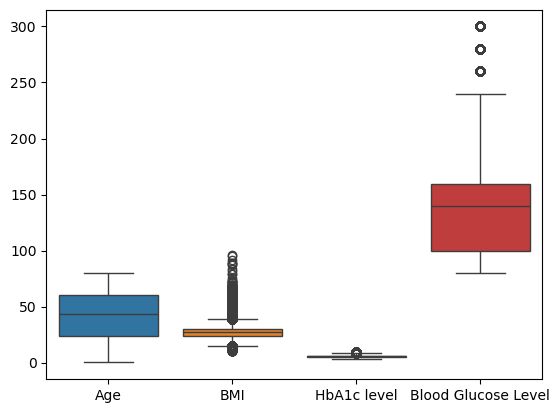

In [27]:
binary_cols = ['Hypertension', 'Heart Disease', 'Diabetes']
other_cols = [col for col in df_predict.columns if col not in binary_cols]
df_predict[df_predict[binary_cols].isin([0,1]).all(axis=1)==False]

sns.boxplot(data=df_predict[other_cols])

From the boxplot, we can see there are multiple outliers for the BMI column data and a few in the blood glucose level 
column data

In [28]:
# Clean the data
d_predict = df_predict.drop_duplicates()  #drop duplicate 
df_clean = df_predict.dropna(how='any')  #drop missing values

print("\nAfter dropping rows with missing values:")
print("Cleaned shape:", df_clean.shape)
print("Remaining missing values:", df_clean.isnull().sum().sum())


After dropping rows with missing values:
Cleaned shape: (100000, 9)
Remaining missing values: 0


Clean data refers to the detecting and correction of incomplete, incorrect, inaccurate or irrelevant data. Since there were
no missing values to start it, the size of the dataset remains the same after dropping the missing values. There was
no duplicate data found as well. 

In [29]:
df_predict[['BMI', 'Blood Glucose Level', 'Diabetes']].describe() #summary statistics

,BMI,Blood Glucose Level,Diabetes
count,100000.000000,100000.000000,100000.000000
mean,27.320767,138.058060,0.085000
std,6.636783,40.708136,0.278883
min,10.010000,80.000000,0.000000
25%,23.630000,100.000000,0.000000
50%,27.320000,140.000000,0.000000
75%,29.580000,159.000000,0.000000
max,95.690000,300.000000,1.000000


In [ ]:
df_predict.to_csv('data/02-processed/diabetes_prediction.csv')

## Ethics

Instructions: Keep the contents of this cell. For each item on the checklist
-  put an X there if you've considered the item
-  IF THE ITEM IS RELEVANT place a short paragraph after the checklist item discussing the issue.
  
Items on this checklist are meant to provoke discussion among good-faith actors who take their ethical responsibilities seriously. Your teams will document these discussions and decisions for posterity using this section.  You don't have to solve these problems, you just have to acknowledge any potential harm no matter how unlikely.

Here is a [list of real world examples](https://deon.drivendata.org/examples/) for each item in the checklist that can refer to.

[![Deon badge](https://img.shields.io/badge/ethics%20checklist-deon-brightgreen.svg?style=popout-square)](http://deon.drivendata.org/)

### A. Data Collection
 - [X] **A.1 Informed consent**: If there are human subjects, have they given informed consent, where subjects affirmatively opt-in and have a clear understanding of the data uses to which they consent?
    > Data were obtained from reputable public sources that report only anonymized and consented information. We reviewed each dataset’s documentation to confirm that participants had consented to data use for research purposes.
 - [X] **A.2 Collection bias**: Have we considered sources of bias that could be introduced during data collection and survey design and taken steps to mitigate those?
    > We discussed that there may be bias based on who participated in the surveys or clinical studies (such as being limited to certain regions or demographics). These biases could affect how well results generalize to global populations, affecting our results.
 - [X] **A.3 Limit PII exposure**: Have we considered ways to minimize exposure of personally identifiable information (PII) for example through anonymization or not collecting information that isn't relevant for analysis?
    > Our datasets contain only anonymized variables and no identifiers. Also, we acknowledge that biases may arise from limited participation in certain regions or demographics. To address this, we plan to review documentation from the data sources to identify underrepresented groups, and we will note these limitations explicitly in our report. When possible, we will supplement the data with more diverse samples or apply stratified sampling techniques to ensure balanced representation across demographics
 - [X] **A.4 Downstream bias mitigation**: Have we considered ways to enable testing downstream results for biased outcomes (e.g., collecting data on protected group status like race or gender)?
    > We plan to evaluate potential downstream biases by comparing model performance across relevant subgroups (such as gender, ethnicity). This will help us identify whether certain populations are disproportionately affected by model outcomes and guide any needed data rebalancing or feature adjustments

### B. Data Storage
 - [X] **B.1 Data security**: Do we have a plan to protect and secure data (e.g., encryption at rest and in transit, access controls on internal users and third parties, access logs, and up-to-date software)?
    > We will make sure to use secure local storage and private repositories for our project puropses, and keep all datasets where access will be restricted to team members via version-controlled platforms.
 - [X] **B.2 Right to be forgotten**: Do we have a mechanism through which an individual can request their personal information be removed?
   > Since the datasets are publicly available and anonymized, removal requests are not actually feasible. However, if a data provider revises or removes the dataset, we will ensure that our project reflects those changes.
 - [X] **B.3 Data retention plan**: Is there a schedule or plan to delete the data after it is no longer needed?
   > The data will be available even after our uses, only for educational and reproducibility purposes and not for any medical diagnostic reasons.

### C. Analysis
 - [X] **C.1 Missing perspectives**: Have we sought to address blindspots in the analysis through engagement with relevant stakeholders (e.g., checking assumptions and discussing implications with affected communities and subject matter experts)?
    > We will consult external research and expert discussions to incorporate diverse viewpoints and avoid one-dimensional assumptions. When possible, we’ll review literature on underrepresented health factors to broaden context.
 - [X] **C.2 Dataset bias**: Have we examined the data for possible sources of bias and taken steps to mitigate or address these biases (e.g., stereotype perpetuation, confirmation bias, imbalanced classes, or omitted confounding variables)?
    >  We need to further evaulate how these biases may affect our data, as imbalanced classes may affect our conclusion in a negative manner
 - [X] **C.3 Honest representation**: Are our visualizations, summary statistics, and reports designed to honestly represent the underlying data?
    >  Confusing visualizations will affect how our research is recieved by our audience and honestly designed reports are key for genuinely reaching a conclusion. We will design clear, accurate visualizations that avoid exaggerating trends or hiding variability. All summary statistics will include uncertainty measures, and we’ll avoid misleading data transformations or selective reporting.
 - [X] **C.4 Privacy in analysis**: Have we ensured that data with PII are not used or displayed unless necessary for the analysis?
    >Since the dataset is anonymized, no PII will appear in analysis or outputs. We will also avoid identifiable information in any figures, even indirectly.
 - [X] **C.5 Auditability**: Is the process of generating the analysis well documented and reproducible if we discover issues in the future?
    > Our workflow will be fully documented in version-controlled notebooks with clear preprocessing, modeling, and evaluation steps, enabling full reproducibility and transparency.

### D. Modeling
 - [X] **D.1 Proxy discrimination**: Have we ensured that the model does not rely on variables or proxies for variables that are unfairly discriminatory?
    > We will review model inputs to ensure they do not unintentionally serve as proxies for protected attributes (such as race or gender). If such correlations are found, we will test models with and without these variables to assess impact.
 - [X] **D.2 Fairness across groups**: Have we tested model results for fairness with respect to different affected groups (e.g., tested for disparate error rates)?
    > We will test model performance metrics across demographic subgroups to evaluate fairness. If disparities are observed, we will apply bias mitigation techniques such as reweighting or fairness-constrained optimization.
 - [X] **D.3 Metric selection**: Have we considered the effects of optimizing for our defined metrics and considered additional metrics?
    > Beyond standard accuracy-based metrics, we will also monitor other factors to make sure that model performance does not favor one group over another. This allows a more balanced evaluation of our data.
 - [X] **D.4 Explainability**: Can we explain in understandable terms a decision the model made in cases where a justification is needed?
    > We will use interpretable modeling techniques and visualize key feature contributions to explain model predictions. Interpretability will be prioritized over complexity where possible.
 - [X] **D.5 Communicate limitations**: Have we communicated the shortcomings, limitations, and biases of the model to relevant stakeholders in ways that can be generally understood?
    > Important to establish the foundation for our research and make sure our findings are digestible by most people. We will also explicitly describe any of our assumptions, highlight possible data gaps, and take note of potential biases in all documentation and presentations to ensure readers can properly understand our conclusions.

### E. Deployment
 - [X] **E.1 Monitoring and evaluation**: Do we have a clear plan to monitor the model and its impacts after it is deployed (e.g., performance monitoring, regular audit of sample predictions, human review of high-stakes decisions, reviewing downstream impacts of errors or low-confidence decisions, testing for concept drift)?
    > We will regularly check how well our model performs using new or updated data to make sure it stays reliable. To ensure fairness, we’ll review results for different groups and note any differences. We’ll also keep clear records of all results and model updates so any issues or changes can be easily tracked and understood.
 - [X] **E.2 Redress**: Have we discussed with our organization a plan for response if users are harmed by the results (e.g., how does the data science team evaluate these cases and update analysis and models to prevent future harm)?
    > Since data are anonymized, individuals cannot be directly affected. However, we will remain open to academic critique and revise our methods if concerns about fairness, transparency, or misinterpretation arise.
 - [X] **E.3 Roll back**: Is there a way to turn off or roll back the model in production if necessary?
    > Because this model is only for our research purposes, rollback means returning to an earlier version using our version control system. We will clearly record any major changes so others can reproduce our work.
 - [X] **E.4 Unintended use**: Have we taken steps to identify and prevent unintended uses and abuse of the model and do we have a plan to monitor these once the model is deployed?
    > The analysis is strictly for research purposes and to identify a possible issue. We plan to explicitly discourage any use of the model or dataset for personal medical diagnosis or decision making in any way.

## Team Expectations 

* Everyone must fill out a when2meet (Anagha, Vrindha, Zoya, Isaac) every week to decide their availability and must block a minimum of 3 hours to work on this project. We will pick the time that works best for everyone and meet in person (library) to work on the project. 
* We will use a shared google sheet to discuss any issues and progress that occurs individually outside of the meeting times.
* The project manager - Anagha K will make sure that everyone splits the tasks equally and finishes them in a timely manner.
* We will make our own branches and work on our assigned tasks, which will be merged with the master branch after the task is completed.
* We will be in constant communication in our group chat and let each other know when the task is completed or if any issues need to be resolved.

## Project Timeline Proposal

| Meeting Date  | Meeting Time| Completed Before Meeting  | Discuss at Meeting |
|---|---|---|---|
| 10/28  |  4 PM | Read & Think about COGS 108 expectations; brainstorm topics/questions  | Determine best form of communication; Discuss and decide on final project topic; discuss hypothesis; begin background research | 
| 10/28  |  4 PM | Do background research on topic | Discuss ideal dataset(s) and ethics; draft project proposal | 
| 10/29  | 8 PM  | Edit, finalize, and submit proposal; Search for datasets  | Discuss Wrangling and possible analytical approaches; Assign group members to lead each specific part   |
| 11/11|  10 AM | Import & Wrangle Data ; EDA | Review/Edit wrangling/EDA; Discuss Analysis Plan   |
| 11/12  |  5 PM | Finalize wrangling/EDA; Begin Analysis | Discuss/edit Analysis; Complete project check-in |
|  11/29 | 5 PM | Complete analysis; Draft results/conclusion/discussion| Discuss/edit full project |
| 12/8  | Before 11:59 PM  | NA | Turn in Final Project & Group Project Surveys |